In [2]:
%pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
import requests

In [4]:
books_df = pd.read_csv("../../data/books.csv", encoding="utf-8")

books_df.head()

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0


In [5]:
books_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6810 entries, 0 to 6809
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   isbn13          6810 non-null   int64  
 1   isbn10          6810 non-null   str    
 2   title           6810 non-null   str    
 3   subtitle        2381 non-null   str    
 4   authors         6738 non-null   str    
 5   categories      6711 non-null   str    
 6   thumbnail       6481 non-null   str    
 7   description     6548 non-null   str    
 8   published_year  6804 non-null   float64
 9   average_rating  6767 non-null   float64
 10  num_pages       6767 non-null   float64
 11  ratings_count   6767 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 638.6 KB


In [6]:
# the dataset doesn't need any table conversions

In [7]:
%pip install pillow requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Books with thumbnail image: 6481


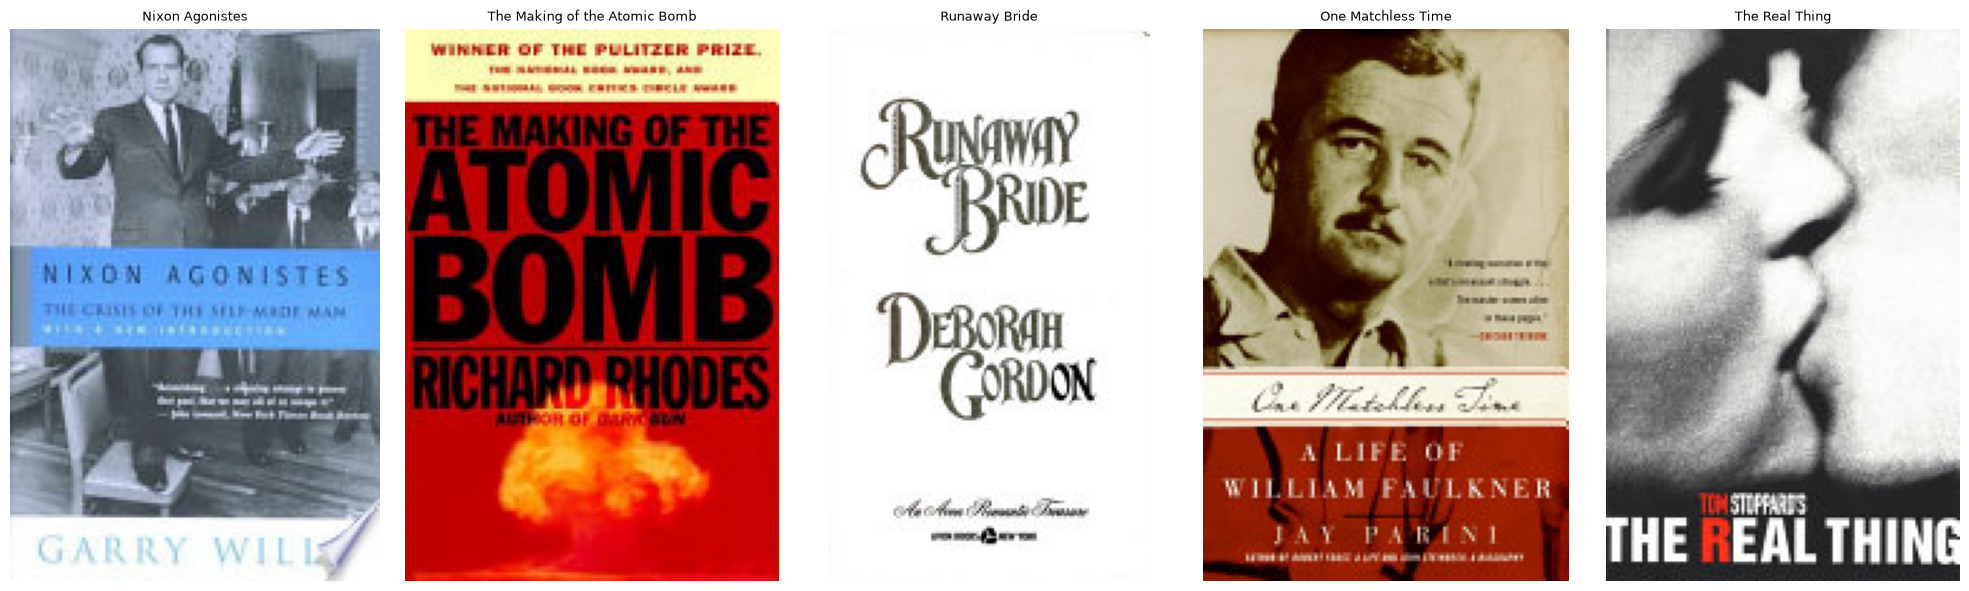

In [8]:
# keeping only the books with thumbnail images, for aesthetic purposes

df_2 = books_df[books_df["thumbnail"].notna() & (books_df["thumbnail"].str.strip() != "")].copy()

print(f"Books with thumbnail image: {len(df_2)}")

example_books = df_2.sample(5, random_state=42)

fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for ax, (_, livro) in zip(axes, example_books.iterrows()):
    try:
        reply = requests.get(livro["thumbnail"], timeout=10)
        reply.raise_for_status()

        img = Image.open(BytesIO(reply.content))
        ax.imshow(img)
        ax.set_title(livro["title"][:30], fontsize=9)
        ax.axis("off")

    except Exception as erro:
        ax.set_title("Error loading image", fontsize=8)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
df_2.info()

<class 'pandas.DataFrame'>
Index: 6481 entries, 0 to 6809
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   isbn13          6481 non-null   int64  
 1   isbn10          6481 non-null   str    
 2   title           6481 non-null   str    
 3   subtitle        2266 non-null   str    
 4   authors         6420 non-null   str    
 5   categories      6432 non-null   str    
 6   thumbnail       6481 non-null   str    
 7   description     6326 non-null   str    
 8   published_year  6481 non-null   float64
 9   average_rating  6448 non-null   float64
 10  num_pages       6448 non-null   float64
 11  ratings_count   6448 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 658.2 KB


In [10]:
# removing books with missing important info

important_columns = ["authors", "categories", "description", "average_rating", "num_pages", "ratings_count"]

df_2 = df_2.dropna(subset=important_columns).copy()

print(f"Number of books with all essential columns: {len(df_2)}")
print("\nNull values:")
print(df_2.isnull().sum())

Number of books with all essential columns: 6215

Null values:
isbn13               0
isbn10               0
title                0
subtitle          4033
authors              0
categories           0
thumbnail            0
description          0
published_year       0
average_rating       0
num_pages            0
ratings_count        0
dtype: int64


In [11]:
df_2.info()

<class 'pandas.DataFrame'>
Index: 6215 entries, 0 to 6809
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   isbn13          6215 non-null   int64  
 1   isbn10          6215 non-null   str    
 2   title           6215 non-null   str    
 3   subtitle        2182 non-null   str    
 4   authors         6215 non-null   str    
 5   categories      6215 non-null   str    
 6   thumbnail       6215 non-null   str    
 7   description     6215 non-null   str    
 8   published_year  6215 non-null   float64
 9   average_rating  6215 non-null   float64
 10  num_pages       6215 non-null   float64
 11  ratings_count   6215 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 631.2 KB


In [12]:
# checking if the books are unique

print("ISBN-13:", df_2["isbn13"].nunique())
print("ISBN-10:", df_2["isbn10"].nunique())

print("TOTAL UNIQUE BOOKS:", len(df_2))

ISBN-13: 6215
ISBN-10: 6215
TOTAL UNIQUE BOOKS: 6215


# Dataset analysis 

In [13]:
# 
df_2.info()

<class 'pandas.DataFrame'>
Index: 6215 entries, 0 to 6809
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   isbn13          6215 non-null   int64  
 1   isbn10          6215 non-null   str    
 2   title           6215 non-null   str    
 3   subtitle        2182 non-null   str    
 4   authors         6215 non-null   str    
 5   categories      6215 non-null   str    
 6   thumbnail       6215 non-null   str    
 7   description     6215 non-null   str    
 8   published_year  6215 non-null   float64
 9   average_rating  6215 non-null   float64
 10  num_pages       6215 non-null   float64
 11  ratings_count   6215 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 631.2 KB


In [14]:
df_2.to_csv("../../data/books-processed.csv", index=False, encoding="utf-8")